In [4]:
#PROJECT TITLE

#Public Transport Utilization Trends – An Exploratory Data Analysis Using Python

#INTRODUCTION

#This project analyses public transport utilization data using Python.
#It explores passenger demand, bus occupancy, route utilization,
#and fuel consumption through statistical analysis and data visualization.

#OBJECTIVES

#1. To analyse passenger utilization across different months.
#2. To compare occupancy rates among bus types.
#3. To identify routes with high passenger demand.
#4. To examine the relationship between distance travelled and fuel consumption.
#5. To present findings using graphs and statistical summaries.

#TOOLS USED

#Python, Pandas, NumPy, Matplotlib, and Google Colab.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [7]:
from google.colab import files

uploaded = files.upload()

Saving APSRTC Public Transportation Data.csv to APSRTC Public Transportation Data.csv


In [9]:
df = pd.read_csv("APSRTC Public Transportation Data.csv")

print("Dataset loaded successfully")
display(df.head())

Dataset loaded successfully


,bus_id,route,bus_type,depot,date,capacity,passengers,occupancy_rate,distance_km,fare_per_passenger,revenue,fuel_consumed_liters,month,day_of_week
0,AP0001,Kurnool-Hyderabad,Volvo AC,Guntur,26-11-2024,49,32,65.77,326.58,908.75,29079.96,75.73,November,Tuesday
1,AP0002,Anantapur-Bangalore,Sleeper,Tirupati,03-10-2024,36,14,41.42,291.91,770.66,10789.30,71.55,October,Thursday
2,AP0003,Hyderabad-Vijayawada,Volvo AC,Vijayawada,06-07-2024,49,43,89.26,238.41,277.49,11932.08,47.85,July,Saturday
3,AP0004,Eluru-Hyderabad,Semi-Sleeper,Kurnool,02-11-2024,63,52,83.97,347.55,199.64,10381.38,72.64,November,Saturday
4,AP0005,Kurnool-Hyderabad,Sleeper,Hyderabad,20-09-2024,44,31,70.62,444.88,591.89,18348.44,77.17,September,Friday


In [10]:
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows and columns:
(1000, 14)

Column names:
['bus_id', 'route', 'bus_type', 'depot', 'date', 'capacity', 'passengers', 'occupancy_rate', 'distance_km', 'fare_per_passenger', 'revenue', 'fuel_consumed_liters', 'month', 'day_of_week']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   bus_id                1000 non-null   object 
 1   route                 1000 non-null   object 
 2   bus_type              1000 non-null   object 
 3   depot                 1000 non-null   object 
 4   date                  1000 non-null   object 
 5   capacity              1000 non-null   int64  
 6   passengers            1000 non-null   int64  
 7   occupancy_rate        1000 non-null   float64
 8   distance_km           1000 non-null   float64
 9   fare_per_passenger    1000 non-null   float64
 10  revenue     

In [11]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values in each column:
bus_id                  0
route                   0
bus_type                0
depot                   0
date                    0
capacity                0
passengers              0
occupancy_rate          0
distance_km             0
fare_per_passenger      0
revenue                 0
fuel_consumed_liters    0
month                   0
day_of_week             0
dtype: int64

Duplicate records:
0


In [12]:
print("Statistical Summary:")
display(df.describe())

print("\nTotal Passengers:")
print(df["passengers"].sum())

print("\nAverage Occupancy Rate:")
print(df["occupancy_rate"].mean())

Statistical Summary:


,capacity,passengers,occupancy_rate,distance_km,fare_per_passenger,revenue,fuel_consumed_liters
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,53.290000,36.832000,69.990930,374.287420,484.358130,16955.578420,85.414540
std,7.917739,11.204433,18.038766,123.690147,248.082856,9088.421846,34.608981
min,36.000000,7.000000,20.000000,62.870000,100.000000,2143.220000,14.380000
25%,49.000000,29.000000,58.402500,282.617500,277.207500,10202.355000,61.175000
50%,55.000000,37.000000,71.190000,354.800000,426.305000,15126.200000,79.095000
75%,59.000000,45.000000,83.382500,458.635000,675.072500,21682.367500,104.192500
max,63.000000,63.000000,100.000000,699.590000,1328.870000,54705.730000,271.180000



Total Passengers:
36832

Average Occupancy Rate:
69.99092999999999


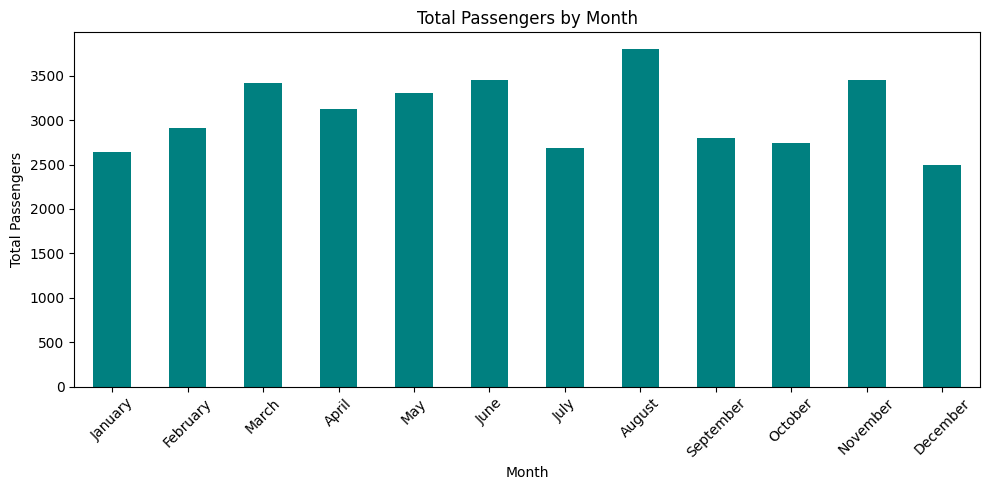

In [13]:
monthly_passengers = df.groupby("month")["passengers"].sum()

monthly_passengers = monthly_passengers.reindex([
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]).dropna()

plt.figure(figsize=(10, 5))
monthly_passengers.plot(kind="bar", color="teal")

plt.title("Total Passengers by Month")
plt.xlabel("Month")
plt.ylabel("Total Passengers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

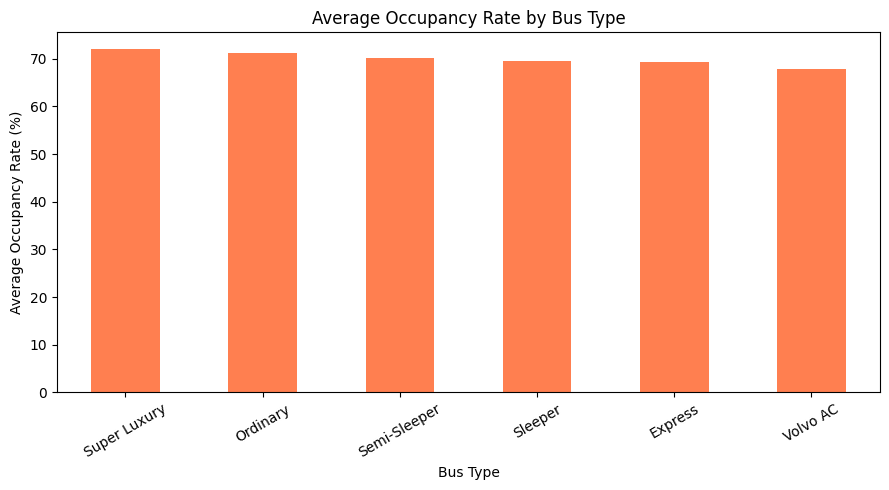

In [14]:
occupancy = df.groupby("bus_type")["occupancy_rate"].mean()
occupancy = occupancy.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
occupancy.plot(kind="bar", color="coral")

plt.title("Average Occupancy Rate by Bus Type")
plt.xlabel("Bus Type")
plt.ylabel("Average Occupancy Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

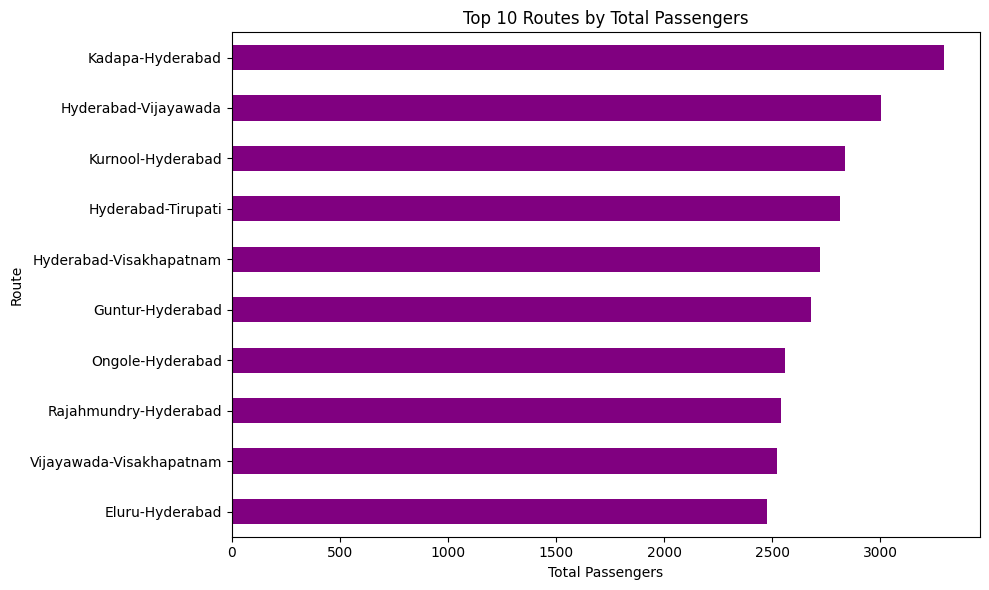

In [15]:
top_routes = df.groupby("route")["passengers"].sum()
top_routes = top_routes.sort_values(ascending=False).head(10)
top_routes = top_routes.sort_values()

plt.figure(figsize=(10, 6))
top_routes.plot(kind="barh", color="purple")

plt.title("Top 10 Routes by Total Passengers")
plt.xlabel("Total Passengers")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

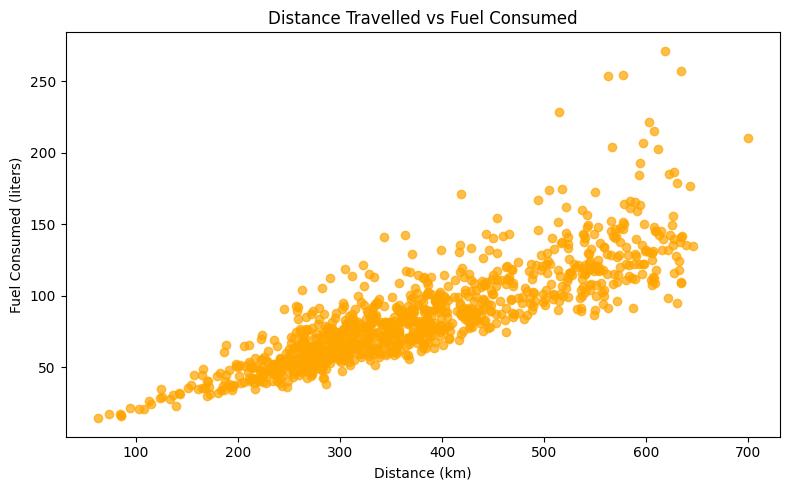

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["distance_km"],
    df["fuel_consumed_liters"],
    color="orange",
    alpha=0.7
)

plt.title("Distance Travelled vs Fuel Consumed")
plt.xlabel("Distance (km)")
plt.ylabel("Fuel Consumed (liters)")
plt.tight_layout()
plt.show()

In [17]:
correlation = df["distance_km"].corr(
    df["fuel_consumed_liters"]
)

print("Correlation between distance and fuel consumption:")
print(round(correlation, 3))

Correlation between distance and fuel consumption:
0.844


In [18]:
print("PROJECT FINDINGS")

print("\nMonth with highest passenger total:")
print(monthly_passengers.idxmax())

print("\nMonth with lowest passenger total:")
print(monthly_passengers.idxmin())

print("\nBus type with highest average occupancy:")
print(occupancy.idxmax())

print("\nRoute with highest passenger total:")
print(df.groupby("route")["passengers"].sum().idxmax())

print("\nDistance and fuel correlation:")
print(round(correlation, 3))

PROJECT FINDINGS

Month with highest passenger total:
August

Month with lowest passenger total:
December

Bus type with highest average occupancy:
Super Luxury

Route with highest passenger total:
Kadapa-Hyderabad

Distance and fuel correlation:
0.844


CONCLUSION
This project uses Python to perform exploratory data analysis on public transport utilization data. Pandas is used for data processing and statistical analysis, while Matplotlib is used to visualize passenger demand, occupancy rates, route utilization, and fuel consumption. The graphs and statistical results help identify patterns in the dataset. The findings can support further investigation into public transport demand and operational efficiency.